# Problem 4: Credit Card Default Prediction
## Part 1: EDA, Data Quality & Feature Engineering

**Candidate:** Chetsadaphon Kanthiya 
**Dataset:** UCI Default of Credit Card Clients (30,000 records) 

---

## Requirements Coverage:
 **Q1 (17%):** EDA - distributions, class imbalance, anomalies 
 **Q2 (13%):** Feature engineering - six shared features for utilization, payment ratio, delays, bill trend, and payment volatility 

**Final Output:** 19 model features (12 core + 6 engineered + SEX) and a stratified 70/30 train/holdout split


## 1. Setup

In [1]:
# โหลดไลบรารีสำหรับจัดการข้อมูล วิเคราะห์ และวาดกราฟ
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split

# Import shared cleaning and feature-engineering functions
from preprocessing import load_and_clean_data, engineer_features, select_features

# Config
SEED = 42
np.random.seed(SEED)
warnings.filterwarnings('ignore')

# Plotting
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (12, 6)

# Keep Q4-generated data, models, and results organized under output/
REPORT_DIR = os.path.abspath('../../report/q4')
OUTPUT_DIR = os.path.abspath('output')
DATA_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'data')
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'models')
RESULTS_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'results')
os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(DATA_OUTPUT_DIR, exist_ok=True)
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
os.makedirs(RESULTS_OUTPUT_DIR, exist_ok=True)

print(' Setup complete')
print(f' Random seed: {SEED}')
print(f' Figures: {REPORT_DIR}')
print(f' Q4 outputs: {OUTPUT_DIR}')


 Setup complete
 Random seed: 42
 Figures: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\report\q4
 Q4 outputs: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output


## 2. Data Loading & Quality Assessment

In [2]:
# โหลดข้อมูลดิบและตรวจโครงสร้างกับคุณภาพเบื้องต้น
# Load raw data
df_raw = pd.read_excel('data/default of credit card clients.xls', header=1)

print("=" * 70)
print("RAW DATA QUALITY ASSESSMENT")
print("=" * 70)
print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"\nColumn names:\n{df_raw.columns.tolist()}")

# Check missing values
missing = df_raw.isnull().sum()
print(f"\nMissing values: {missing.sum()} (0 expected )")

# Check duplicates
n_dups = df_raw['ID'].duplicated().sum()
print(f"Duplicate IDs: {n_dups} (0 expected )")

df_raw.head(3)

RAW DATA QUALITY ASSESSMENT
Shape: 30,000 rows × 25 columns

Column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Missing values: 0 (0 expected )
Duplicate IDs: 0 (0 expected )


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


### 2.1 Target Variable Analysis

In [3]:
# ตรวจสัดส่วนลูกค้าที่ผิดนัดเพื่อเห็น class imbalance
# Target distribution
target = df_raw['default payment next month']
target_counts = target.value_counts().sort_index()
default_rate = target.mean()

print("=" * 70)
print("TARGET: DEFAULT PAYMENT NEXT MONTH")
print("=" * 70)
print(f"\nNo default (0): {target_counts[0]:,} ({(1-default_rate)*100:.2f}%)")
print(f"Default (1): {target_counts[1]:,} ({default_rate*100:.2f}%)")
print(f"\n Class imbalance: {target_counts[0]/target_counts[1]:.2f}:1")
print(f"→ Solution: Stratified sampling + PR-AUC metric")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
axes[0].bar(['No Default', 'Default'], target_counts.values, 
 color=['#2ecc71', '#e74c3c'], alpha=0.7, edgecolor='black', linewidth=2)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].set_title('Target Distribution', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(target_counts.values):
 axes[0].text(i, v + 500, f'{v:,}\n({v/len(df_raw)*100:.1f}%)', 
 ha='center', fontsize=11, fontweight='bold')

# Pie chart
colors = ['#2ecc71', '#e74c3c']
explode = (0, 0.1)
axes[1].pie(target_counts.values, labels=['No Default', 'Default'],
 autopct='%1.1f%%', startangle=90, colors=colors, explode=explode,
 textprops={'fontsize': 12, 'fontweight': 'bold'}, shadow=True)
axes[1].set_title(f'Imbalance Ratio: {target_counts[0]/target_counts[1]:.1f}:1', 
 fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../../report/q4/q4_01_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n Saved: report/q4/q4_01_target_distribution.png")

TARGET: DEFAULT PAYMENT NEXT MONTH

No default (0): 23,364 (77.88%)
Default (1): 6,636 (22.12%)

 Class imbalance: 3.52:1
→ Solution: Stratified sampling + PR-AUC metric


<Figure size 1400x500 with 2 Axes>


 Saved: report/q4/q4_01_target_distribution.png


### 2.2 Anomaly Detection: Invalid Category Codes

### 2.3 Apply Data Cleaning

In [4]:
# ทำความสะอาดรหัสหมวดหมู่และเตรียม target ด้วยฟังก์ชันกลาง
# Use preprocessing module for cleaning
df_clean = load_and_clean_data()

print("=" * 70)
print("DATA CLEANING APPLIED")
print("=" * 70)
print(f" Renamed: 'default payment next month' → 'default'")
print(f" Fixed EDUCATION: codes 0,5,6 → 4 (Others)")
print(f" Fixed MARRIAGE: code 0 → 3 (Others)")
print(f" Dropped: ID column")
print(f"\nCleaned shape: {df_clean.shape}")

# Verify fixes
print(f"\nVerification:")
print(f" EDUCATION values: {sorted(df_clean['EDUCATION'].unique())}")
print(f" MARRIAGE values: {sorted(df_clean['MARRIAGE'].unique())}")
print(f" Target column: '{df_clean.columns[-1]}'")

DATA CLEANING APPLIED
 Renamed: 'default payment next month' → 'default'
 Fixed EDUCATION: codes 0,5,6 → 4 (Others)
 Fixed MARRIAGE: code 0 → 3 (Others)
 Dropped: ID column

Cleaned shape: (30000, 24)

Verification:
 EDUCATION values: [1, 2, 3, 4]
 MARRIAGE values: [1, 2, 3]
 Target column: 'default'


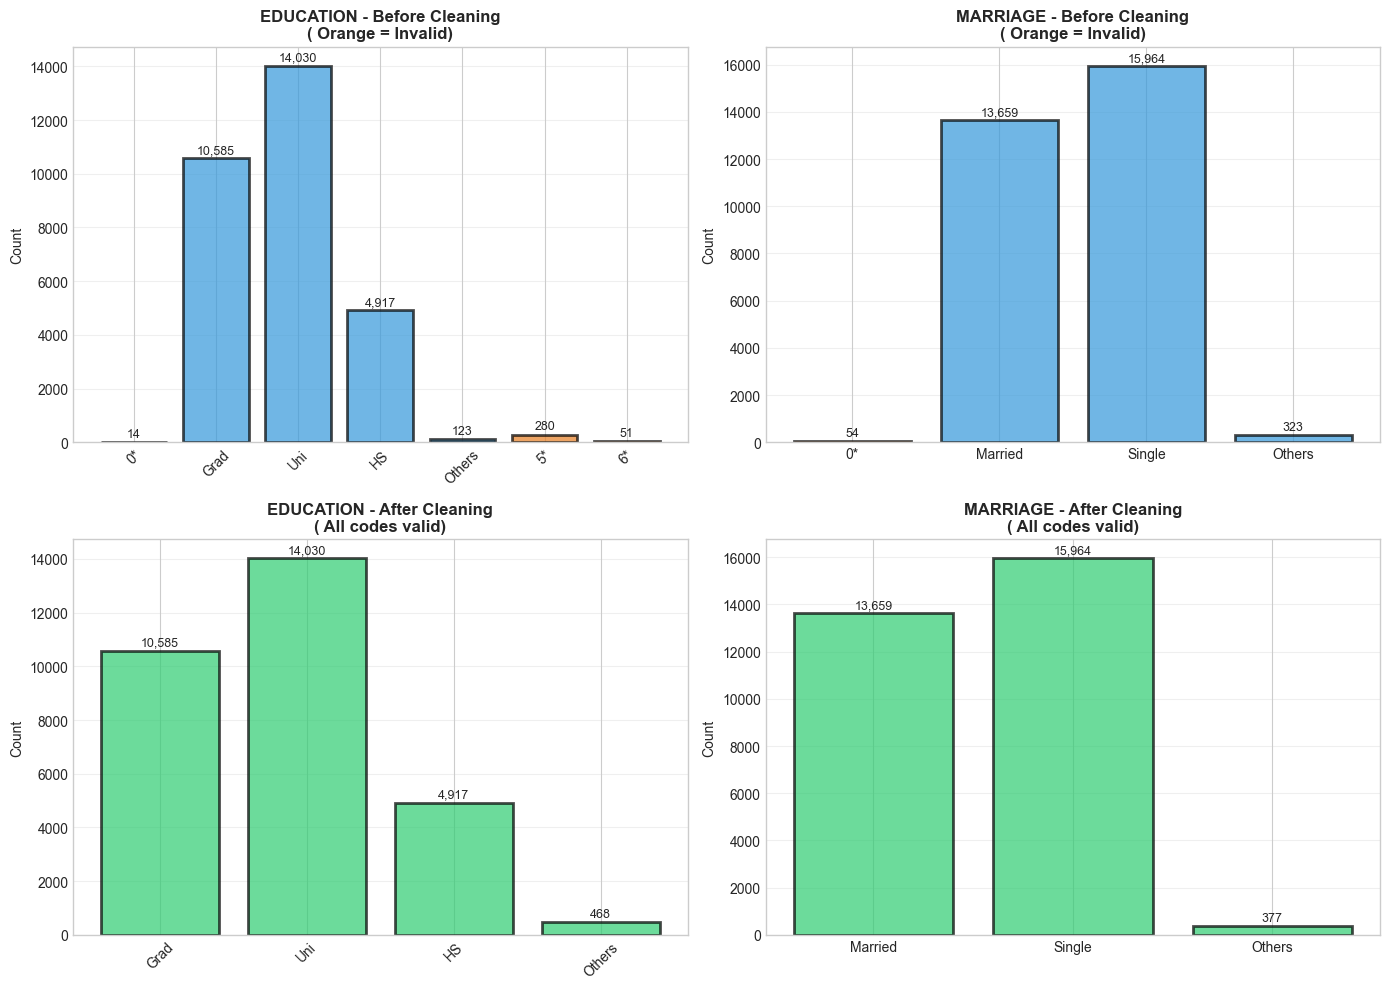


 Saved: report/q4/q4_02_anomalies.png

 Cleaning summary:
 EDUCATION code 4: 123 → 468 (+345 from invalid codes)
 MARRIAGE code 3: 323 → 377 (+54 from invalid codes)


In [5]:
# เปรียบเทียบรหัสหมวดหมู่ก่อนและหลังแก้ค่าผิดปกติ
# Visualization: Before vs After Cleaning
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- BEFORE CLEANING (Raw data) ---
# EDUCATION (Before)
edu_counts_raw = df_raw['EDUCATION'].value_counts().sort_index()
edu_labels_raw = {1: 'Grad', 2: 'Uni', 3: 'HS', 4: 'Others', 
 0: '0*', 5: '5*', 6: '6*'}
edu_names = [edu_labels_raw.get(k, str(k)) for k in edu_counts_raw.index]
colors_edu = ['#e67e22' if k in [0,5,6] else '#3498db' for k in edu_counts_raw.index]
axes[0,0].bar(edu_names, edu_counts_raw.values, color=colors_edu, alpha=0.7, edgecolor='black', linewidth=2)
axes[0,0].set_title('EDUCATION - Before Cleaning\n( Orange = Invalid)', fontsize=12, fontweight='bold')
axes[0,0].set_ylabel('Count')
axes[0,0].tick_params(axis='x', rotation=45)
axes[0,0].grid(axis='y', alpha=0.3)
# Add counts on bars
for i, (name, val) in enumerate(zip(edu_names, edu_counts_raw.values)):
 axes[0,0].text(i, val + 200, f'{val:,}', ha='center', fontsize=9)

# MARRIAGE (Before)
mar_counts_raw = df_raw['MARRIAGE'].value_counts().sort_index()
mar_labels_raw = {1: 'Married', 2: 'Single', 3: 'Others', 0: '0*'}
mar_names = [mar_labels_raw.get(k, str(k)) for k in mar_counts_raw.index]
colors_mar = ['#e67e22' if k == 0 else '#3498db' for k in mar_counts_raw.index]
axes[0,1].bar(mar_names, mar_counts_raw.values, color=colors_mar, alpha=0.7, edgecolor='black', linewidth=2)
axes[0,1].set_title('MARRIAGE - Before Cleaning\n( Orange = Invalid)', fontsize=12, fontweight='bold')
axes[0,1].set_ylabel('Count')
axes[0,1].grid(axis='y', alpha=0.3)
for i, (name, val) in enumerate(zip(mar_names, mar_counts_raw.values)):
 axes[0,1].text(i, val + 200, f'{val:,}', ha='center', fontsize=9)

# --- AFTER CLEANING ---
# EDUCATION (After)
edu_counts_clean = df_clean['EDUCATION'].value_counts().sort_index()
edu_labels_clean = {1: 'Grad', 2: 'Uni', 3: 'HS', 4: 'Others'}
edu_names_clean = [edu_labels_clean[k] for k in edu_counts_clean.index]
axes[1,0].bar(edu_names_clean, edu_counts_clean.values, color='#2ecc71', alpha=0.7, edgecolor='black', linewidth=2)
axes[1,0].set_title('EDUCATION - After Cleaning\n( All codes valid)', fontsize=12, fontweight='bold')
axes[1,0].set_ylabel('Count')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].grid(axis='y', alpha=0.3)
for i, (name, val) in enumerate(zip(edu_names_clean, edu_counts_clean.values)):
 axes[1,0].text(i, val + 200, f'{val:,}', ha='center', fontsize=9)

# MARRIAGE (After)
mar_counts_clean = df_clean['MARRIAGE'].value_counts().sort_index()
mar_labels_clean = {1: 'Married', 2: 'Single', 3: 'Others'}
mar_names_clean = [mar_labels_clean[k] for k in mar_counts_clean.index]
axes[1,1].bar(mar_names_clean, mar_counts_clean.values, color='#2ecc71', alpha=0.7, edgecolor='black', linewidth=2)
axes[1,1].set_title('MARRIAGE - After Cleaning\n( All codes valid)', fontsize=12, fontweight='bold')
axes[1,1].set_ylabel('Count')
axes[1,1].grid(axis='y', alpha=0.3)
for i, (name, val) in enumerate(zip(mar_names_clean, mar_counts_clean.values)):
 axes[1,1].text(i, val + 200, f'{val:,}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('../../report/q4/q4_02_anomalies.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n Saved: report/q4/q4_02_anomalies.png")
print("\n Cleaning summary:")
print(f" EDUCATION code 4: {edu_counts_raw[4]} → {edu_counts_clean[4]} (+{edu_counts_clean[4]-edu_counts_raw[4]} from invalid codes)")
print(f" MARRIAGE code 3: {mar_counts_raw[3]} → {mar_counts_clean[3]} (+{mar_counts_clean[3]-mar_counts_raw[3]} from invalid codes)")

## 3. Exploratory Data Analysis

### 3.1 Payment History (Most Important Features)

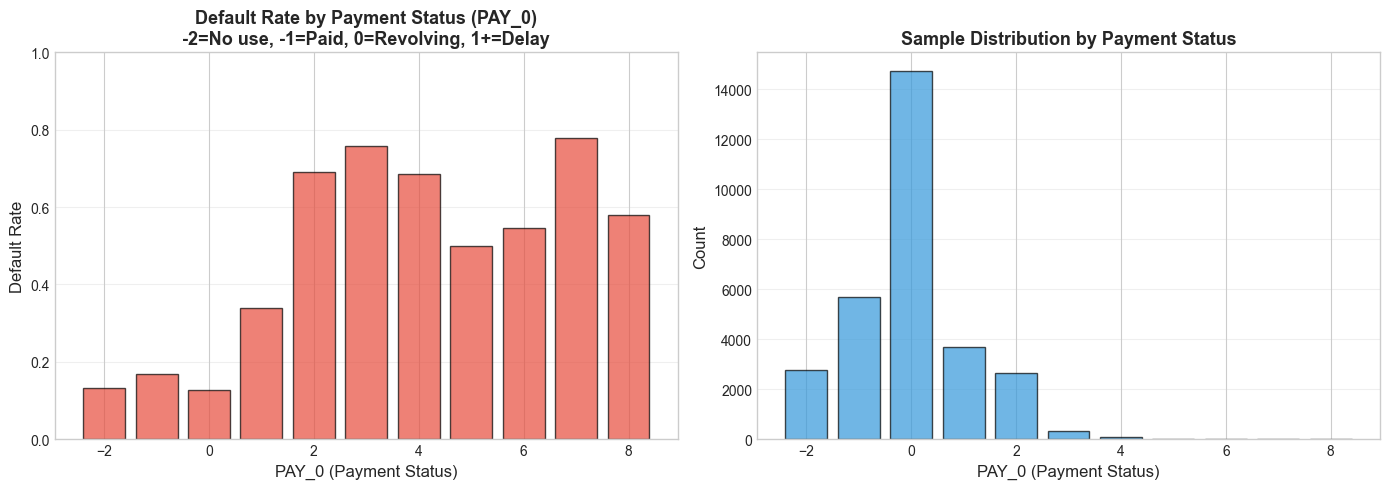


 Saved: report/q4/q4_03_payment_history.png

⭐ Key insight: Higher PAY_0 (more delay) → Higher default rate


In [6]:
# สำรวจความสัมพันธ์ระหว่างประวัติชำระ PAY_0 กับการผิดนัด
# Simplified: Show only PAY_0 (most important) - Default rate by payment status
pay0_default = df_clean.groupby('PAY_0')['default'].agg(['mean', 'count'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Default rate by PAY_0
axes[0].bar(pay0_default.index, pay0_default['mean'], color='#e74c3c', alpha=0.7, edgecolor='black')
axes[0].set_xlabel('PAY_0 (Payment Status)', fontsize=12)
axes[0].set_ylabel('Default Rate', fontsize=12)
axes[0].set_title('Default Rate by Payment Status (PAY_0)\n-2=No use, -1=Paid, 0=Revolving, 1+=Delay', 
 fontsize=13, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim([0, 1])

# Right: Sample counts
axes[1].bar(pay0_default.index, pay0_default['count'], color='#3498db', alpha=0.7, edgecolor='black')
axes[1].set_xlabel('PAY_0 (Payment Status)', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].set_title('Sample Distribution by Payment Status', fontsize=13, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../../report/q4/q4_03_payment_history.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n Saved: report/q4/q4_03_payment_history.png")
print("\n⭐ Key insight: Higher PAY_0 (more delay) → Higher default rate")

### 3.2 Financial Features

FINANCIAL FEATURES

1. LIMIT_BAL (Credit Limit):
count      30000.000000
mean      167484.322667
std       129747.661567
min        10000.000000
25%        50000.000000
50%       140000.000000
75%       240000.000000
max      1000000.000000
Name: LIMIT_BAL, dtype: float64

2. BILL_AMT (6 months):
                   mean           std       min        max
BILL_AMT1  51223.330900  73635.860576 -165580.0   964511.0
BILL_AMT2  49179.075167  71173.768783  -69777.0   983931.0
BILL_AMT3  47013.154800  69349.387427 -157264.0  1664089.0
BILL_AMT4  43262.948967  64332.856134 -170000.0   891586.0
BILL_AMT5  40311.400967  60797.155770  -81334.0   927171.0
BILL_AMT6  38871.760400  59554.107537 -339603.0   961664.0

 ℹ 3,932 negative bill amounts (overpayments, legitimate)

3. PAY_AMT (6 months):
                 mean           std  min        max
PAY_AMT1  5663.580500  16563.280354  0.0   873552.0
PAY_AMT2  5921.163500  23040.870402  0.0  1684259.0
PAY_AMT3  5225.681500  17606.961470  0.0   896040.

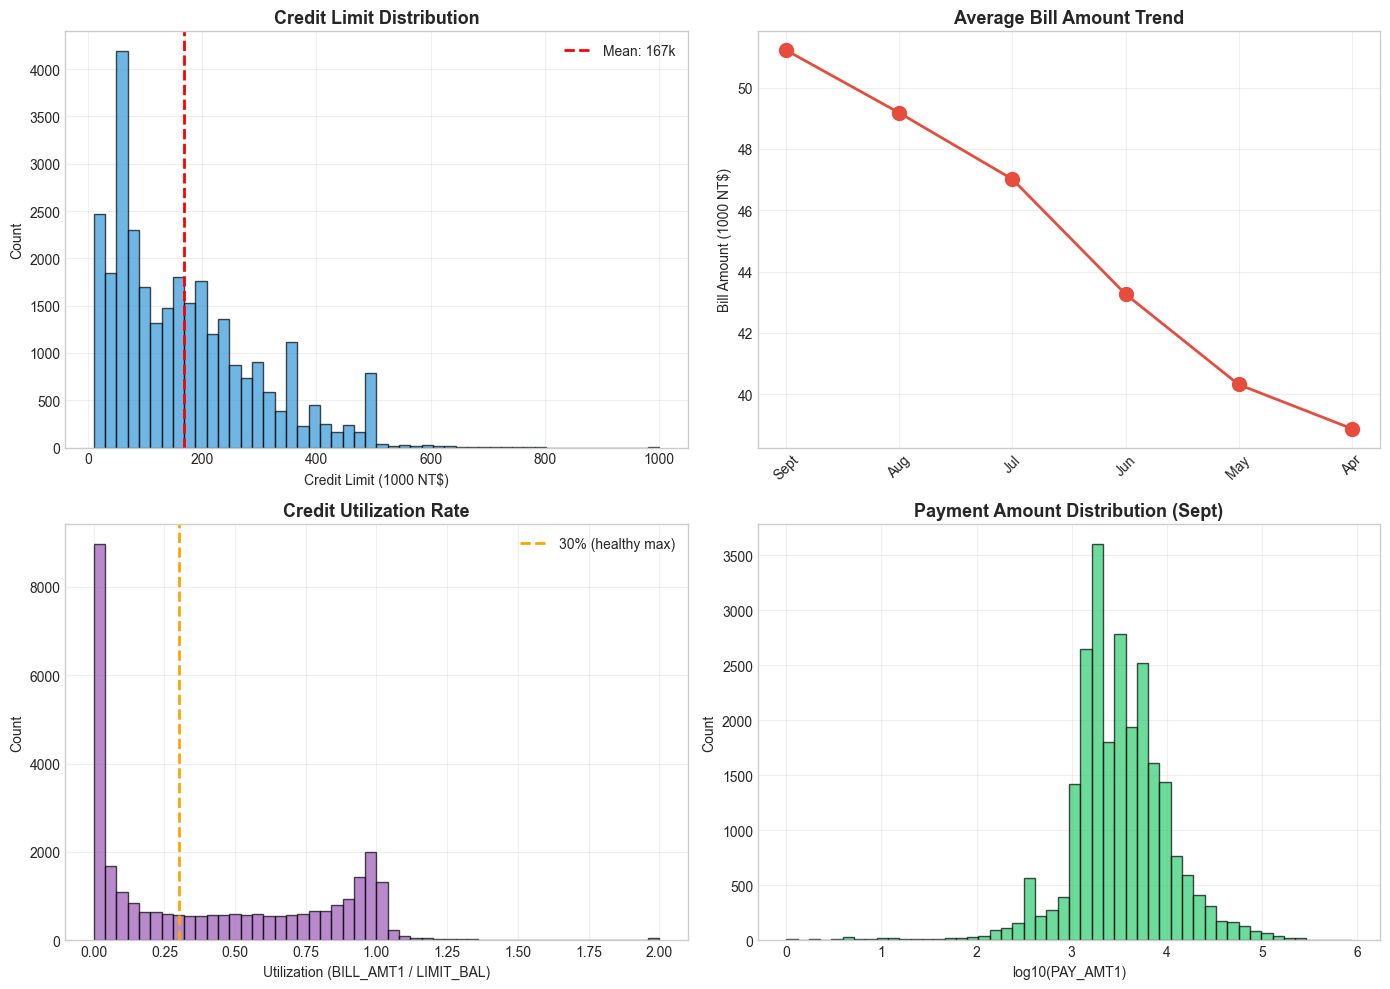


 Saved: report/q4/q4_04_financial_features.png


In [7]:
# สรุปการกระจายของวงเงิน ยอดบิล และยอดชำระ
print("=" * 70)
print("FINANCIAL FEATURES")
print("=" * 70)

# Credit limit
print("\n1. LIMIT_BAL (Credit Limit):")
print(df_clean['LIMIT_BAL'].describe())

# Bill amounts
bill_cols = [f'BILL_AMT{i}' for i in range(1, 7)]
print("\n2. BILL_AMT (6 months):")
print(df_clean[bill_cols].describe().T[['mean', 'std', 'min', 'max']])

# Negative bills (legitimate overpayments)
n_negative = (df_clean[bill_cols] < 0).sum().sum()
print(f"\n ℹ {n_negative:,} negative bill amounts (overpayments, legitimate)")

# Payment amounts
pay_amt_cols = [f'PAY_AMT{i}' for i in range(1, 7)]
print("\n3. PAY_AMT (6 months):")
print(df_clean[pay_amt_cols].describe().T[['mean', 'std', 'min', 'max']])

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Credit limit
axes[0,0].hist(df_clean['LIMIT_BAL']/1000, bins=50, color='#3498db', alpha=0.7, edgecolor='black')
axes[0,0].axvline(df_clean['LIMIT_BAL'].mean()/1000, color='red', linestyle='--', linewidth=2,
 label=f'Mean: {df_clean["LIMIT_BAL"].mean()/1000:.0f}k')
axes[0,0].set_title('Credit Limit Distribution', fontsize=13, fontweight='bold')
axes[0,0].set_xlabel('Credit Limit (1000 NT$)')
axes[0,0].set_ylabel('Count')
axes[0,0].legend()
axes[0,0].grid(alpha=0.3)

# Bill trend
bill_means = df_clean[bill_cols].mean()
months = ['Sept', 'Aug', 'Jul', 'Jun', 'May', 'Apr']
axes[0,1].plot(months, bill_means.values/1000, marker='o', linewidth=2, markersize=10, color='#e74c3c')
axes[0,1].set_title('Average Bill Amount Trend', fontsize=13, fontweight='bold')
axes[0,1].set_ylabel('Bill Amount (1000 NT$)')
axes[0,1].grid(alpha=0.3)
axes[0,1].tick_params(axis='x', rotation=45)

# Utilization rate
util_rate = np.clip(df_clean['BILL_AMT1'] / df_clean['LIMIT_BAL'], 0, 2)
axes[1,0].hist(util_rate, bins=50, color='#9b59b6', alpha=0.7, edgecolor='black')
axes[1,0].axvline(0.3, color='orange', linestyle='--', linewidth=2, label='30% (healthy max)')
axes[1,0].set_title('Credit Utilization Rate', fontsize=13, fontweight='bold')
axes[1,0].set_xlabel('Utilization (BILL_AMT1 / LIMIT_BAL)')
axes[1,0].set_ylabel('Count')
axes[1,0].legend()
axes[1,0].grid(alpha=0.3)

# Payment amounts (log scale)
pay_amt1_nonzero = df_clean[df_clean['PAY_AMT1'] > 0]['PAY_AMT1']
axes[1,1].hist(np.log10(pay_amt1_nonzero), bins=50, color='#2ecc71', alpha=0.7, edgecolor='black')
axes[1,1].set_title('Payment Amount Distribution (Sept)', fontsize=13, fontweight='bold')
axes[1,1].set_xlabel('log10(PAY_AMT1)')
axes[1,1].set_ylabel('Count')
axes[1,1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../../report/q4/q4_04_financial_features.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n Saved: report/q4/q4_04_financial_features.png")

### 3.3 Demographics

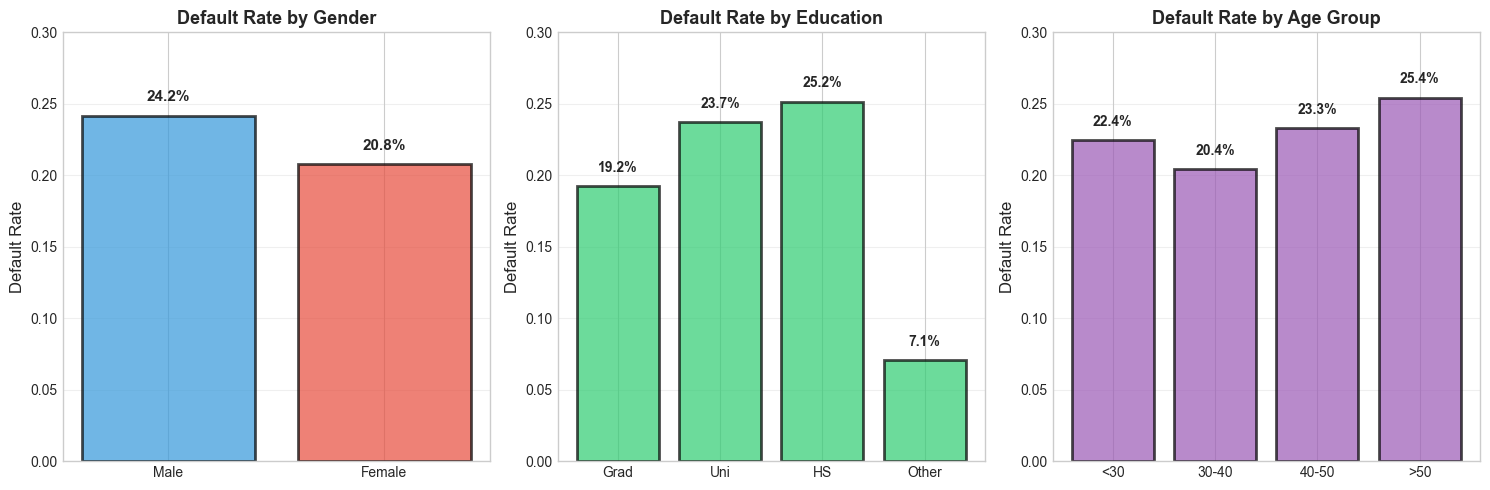


 Saved: report/q4/q4_05_demographics.png

⭐ Insight: Demographics show small differences (~1-3% variation)


In [8]:
# เปรียบเทียบอัตราผิดนัดระหว่างกลุ่มประชากร
# Combined demographics visualization
# Create AGE_GROUP in this cell (may have been lost if df_clean was reloaded)
if 'AGE_GROUP' not in df_clean.columns:
 df_clean['AGE_GROUP'] = pd.cut(df_clean['AGE'], bins=[20, 30, 40, 50, 80], 
 labels=['<30', '30-40', '40-50', '>50'])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# SEX
sex_default = df_clean.groupby('SEX')['default'].mean()
colors_sex = ['#3498db', '#e74c3c']
bars1 = axes[0].bar(['Male', 'Female'], sex_default.values, color=colors_sex, alpha=0.7, edgecolor='black', linewidth=2)
axes[0].set_title('Default Rate by Gender', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Default Rate', fontsize=12)
axes[0].set_ylim([0, 0.3])
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(sex_default.values):
 axes[0].text(i, v + 0.01, f'{v*100:.1f}%', ha='center', fontsize=11, fontweight='bold')

# EDUCATION
edu_default = df_clean.groupby('EDUCATION')['default'].mean()
edu_labels = ['Grad', 'Uni', 'HS', 'Other']
bars2 = axes[1].bar(edu_labels, edu_default.values, color='#2ecc71', alpha=0.7, edgecolor='black', linewidth=2)
axes[1].set_title('Default Rate by Education', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Default Rate', fontsize=12)
axes[1].set_ylim([0, 0.3])
axes[1].grid(axis='y', alpha=0.3)
for i, v in enumerate(edu_default.values):
 axes[1].text(i, v + 0.01, f'{v*100:.1f}%', ha='center', fontsize=10, fontweight='bold')

# AGE
age_default = df_clean.groupby('AGE_GROUP')['default'].mean()
bars3 = axes[2].bar(age_default.index.astype(str), age_default.values, color='#9b59b6', alpha=0.7, edgecolor='black', linewidth=2)
axes[2].set_title('Default Rate by Age Group', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Default Rate', fontsize=12)
axes[2].set_ylim([0, 0.3])
axes[2].grid(axis='y', alpha=0.3)
for i, v in enumerate(age_default.values):
 axes[2].text(i, v + 0.01, f'{v*100:.1f}%', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('../../report/q4/q4_05_demographics.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n Saved: report/q4/q4_05_demographics.png")
print("\n⭐ Insight: Demographics show small differences (~1-3% variation)")

### 3.4 Correlation Analysis

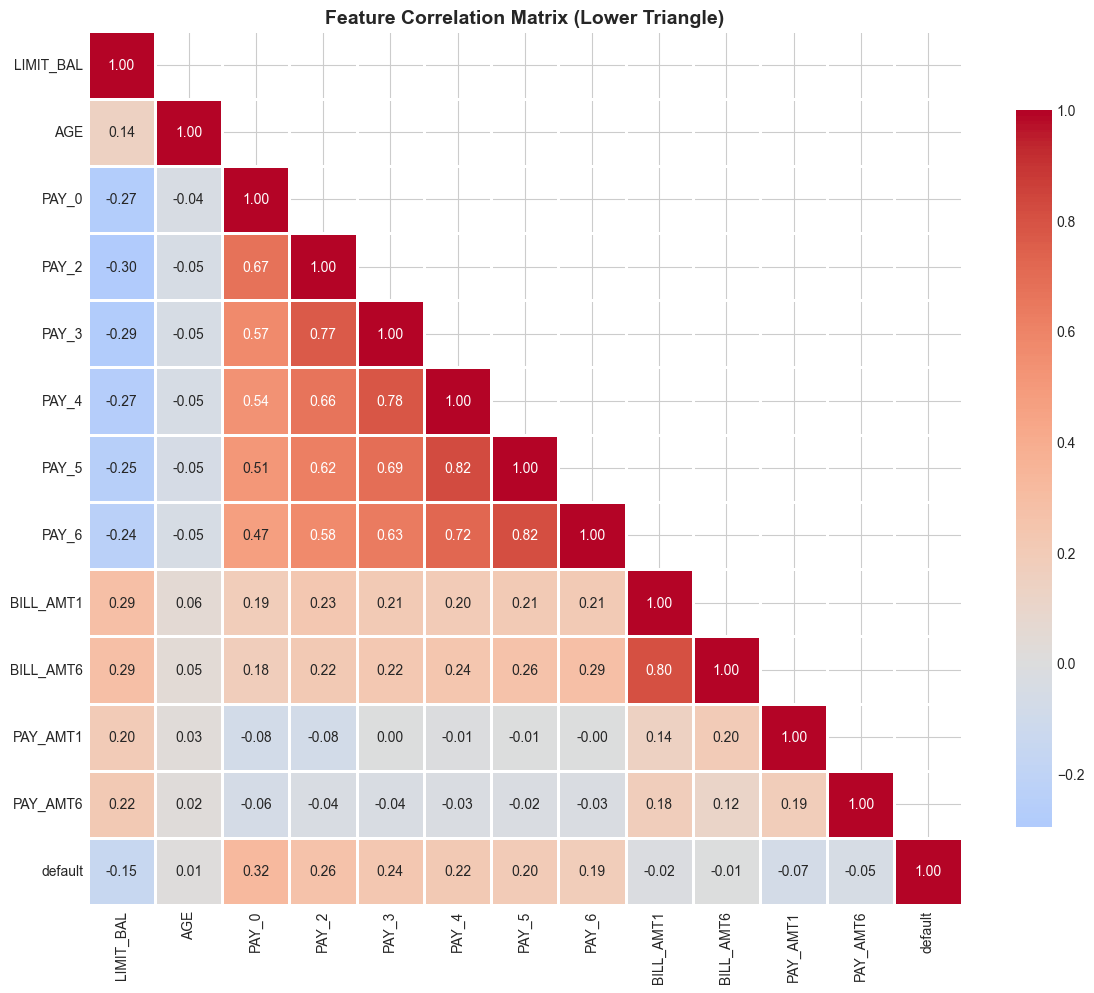

TOP CORRELATIONS WITH DEFAULT (Absolute)
default      1.000000
PAY_0        0.324794
PAY_2        0.263551
PAY_3        0.235253
PAY_4        0.216614
PAY_5        0.204149
PAY_6        0.186866
LIMIT_BAL    0.153520
PAY_AMT1     0.072929
PAY_AMT2     0.058579
PAY_AMT4     0.056827
Name: default, dtype: float64

 Payment-history features (PAY_0 and PAY_2-PAY_6) dominate!

 Saved: report/q4/q4_06_correlation.png


In [9]:
# ตรวจความสัมพันธ์ของตัวแปรหลักด้วย correlation matrix
# Select comprehensive features for correlation (Option A)
key_features = [
 # Demographics (2)
 'LIMIT_BAL', 'AGE',
 # Payment history - complete (6)
 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
 # Bill amounts - key ones (2)
 'BILL_AMT1', 'BILL_AMT6',
 # Payment amounts - key ones (2)
 'PAY_AMT1', 'PAY_AMT6',
 # Target (1)
 'default'
]

corr_matrix = df_clean[key_features].corr()

# Plot
plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
 center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Matrix (Lower Triangle)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../../report/q4/q4_06_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

# Top correlations with target
print("=" * 70)
print("TOP CORRELATIONS WITH DEFAULT (Absolute)")
print("=" * 70)
# Filter numeric columns only (exclude AGE_GROUP string)
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
target_corr = df_clean[numeric_cols].corr()['default'].abs().sort_values(ascending=False)
print(target_corr.head(11))
print("\n Payment-history features (PAY_0 and PAY_2-PAY_6) dominate!")

print("\n Saved: report/q4/q4_06_correlation.png")

## 4. Feature Engineering

**Business Rationale:**
1. **UTIL_RATE**: Credit utilization (BILL/LIMIT) - High usage = stress
2. **PAY_RATIO**: Payment-to-bill ratio - Low = inability to pay
3. **AVG_DELAY**: Average payment delay - Persistent pattern
4. **NUM_DELAYS**: Frequency of delays - Behavior consistency
5. **BILL_TREND**: Debt trajectory - Increasing = trouble
6. **PAY_VOLATILITY**: Payment stability - Erratic = unstable

In [10]:
# สร้างตัวแปรใหม่ที่สะท้อนการใช้วงเงินและพฤติกรรมชำระ
# Apply feature engineering
df_featured = engineer_features(df_clean)

print("=" * 70)
print("FEATURE ENGINEERING")
print("=" * 70)

new_features = ['UTIL_RATE', 'PAY_RATIO', 'AVG_DELAY', 'NUM_DELAYS', 'BILL_TREND', 'PAY_VOLATILITY']

print(f"\n Created {len(new_features)} engineered features:")
for i, feat in enumerate(new_features, 1):
 print(f" {i}. {feat}")

print(f"\n Total features: {df_featured.shape[1]} ({df_featured.shape[1]-1} features + 1 target)")

# Statistics
print("\n" + "=" * 70)
print("ENGINEERED FEATURE STATISTICS")
print("=" * 70)
print(df_featured[new_features].describe().T[['mean', 'std', 'min', 'max']])

# Check quality
n_nan = df_featured[new_features].isnull().sum().sum()
n_inf = np.isinf(df_featured[new_features]).sum().sum()
print(f"\n Quality check: {n_nan} NaN, {n_inf} Inf (both should be 0)")

FEATURE ENGINEERING

 Created 6 engineered features:
 1. UTIL_RATE
 2. PAY_RATIO
 3. AVG_DELAY
 4. NUM_DELAYS
 5. BILL_TREND
 6. PAY_VOLATILITY

 Total features: 31 (30 features + 1 target)

ENGINEERED FEATURE STATISTICS
                        mean           std       min           max
UTIL_RATE           0.422871      0.404623       0.0       2.00000
PAY_RATIO           0.565902      1.253206       0.0       5.00000
AVG_DELAY          -0.182439      0.982176      -2.0       6.00000
NUM_DELAYS          0.834200      1.554303       0.0       6.00000
BILL_TREND      12351.570500  43922.421534 -428791.0  708323.00000
PAY_VOLATILITY   5804.918519  15006.438973       0.0  650098.33882

 Quality check: 0 NaN, 0 Inf (both should be 0)


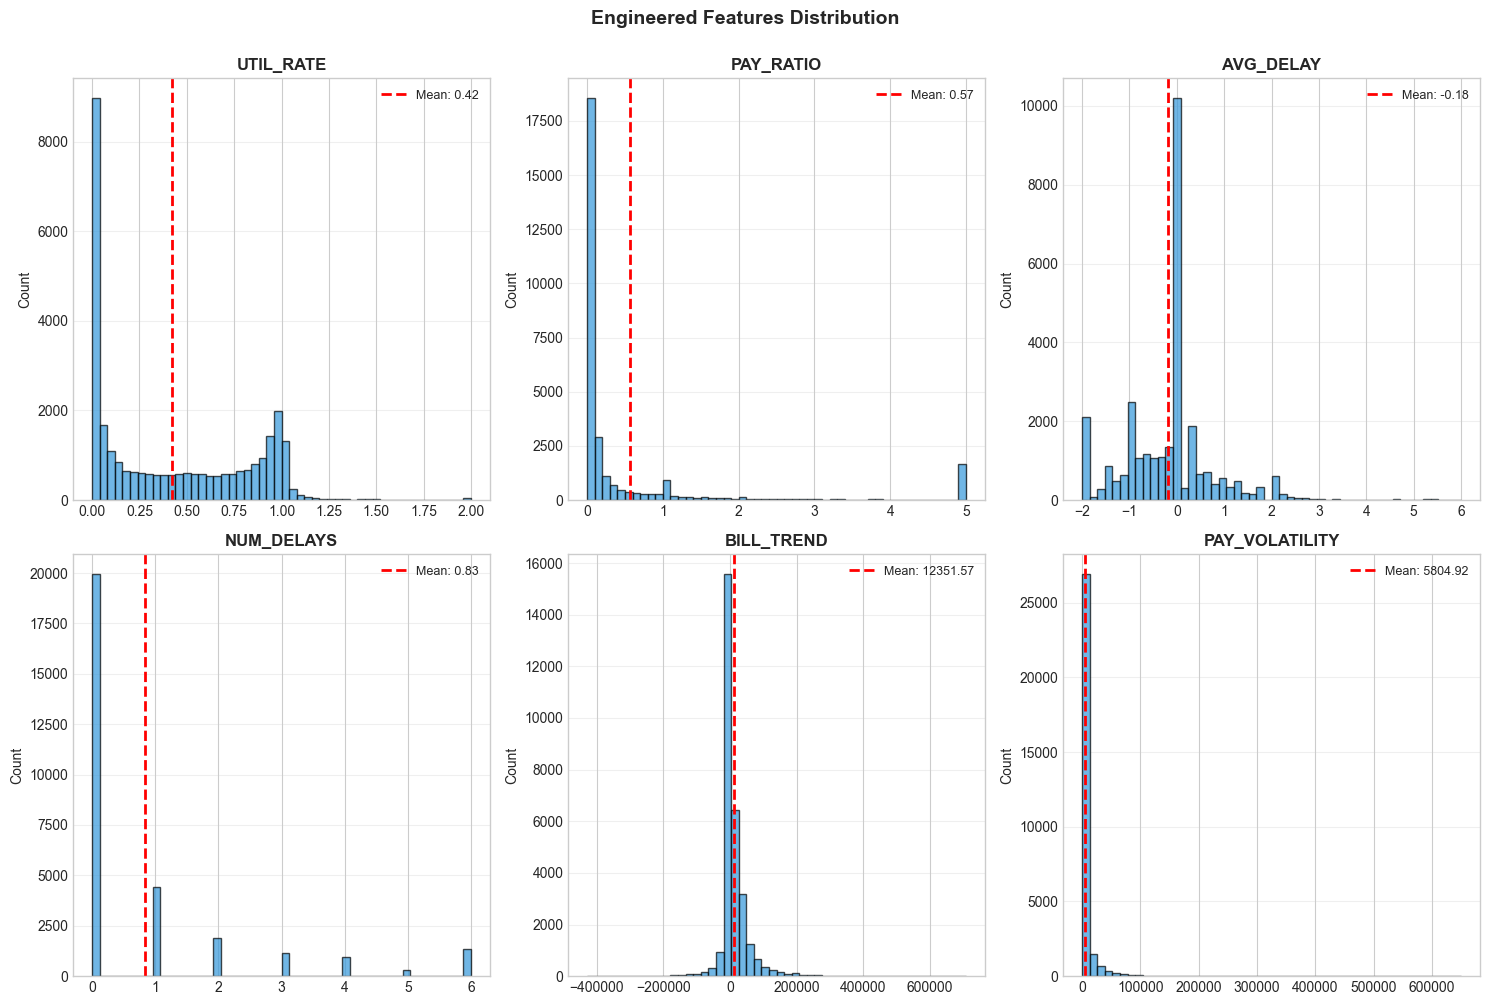

 Saved: report/q4/q4_07_engineered_features.png


In [11]:
# วาดการกระจายของ engineered features เพื่อเช็กค่าที่ได้
# Visualize engineered features
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for i, feat in enumerate(new_features):
 axes[i].hist(df_featured[feat], bins=50, color='#3498db', alpha=0.7, edgecolor='black')
 axes[i].axvline(df_featured[feat].mean(), color='red', linestyle='--', linewidth=2,
 label=f'Mean: {df_featured[feat].mean():.2f}')
 axes[i].set_title(f'{feat}', fontsize=12, fontweight='bold')
 axes[i].set_ylabel('Count')
 axes[i].legend(fontsize=9)
 axes[i].grid(axis='y', alpha=0.3)

plt.suptitle('Engineered Features Distribution', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('../../report/q4/q4_07_engineered_features.png', dpi=150, bbox_inches='tight')
plt.show()

print(" Saved: report/q4/q4_07_engineered_features.png")

## 5. Feature Selection & Final Dataset

**Selected: 18 features (19 with SEX for fairness audit)**

**Tier 1 (12):** PAY_0-6, LIMIT_BAL, BILL_AMT1/6, PAY_AMT1, AGE, EDUCATION 
**Tier 2 (6):** UTIL_RATE, PAY_RATIO, AVG_DELAY, NUM_DELAYS, BILL_TREND, PAY_VOLATILITY 
**Tier 3 (1):** SEX (for fairness audit)

In [12]:
# เลือก features สำหรับโมเดลและเก็บ target แยกต่างหาก
# Select features (include SEX for fairness audit)
X, y = select_features(df_featured, include_sex=True, include_marriage=False)

print("=" * 70)
print("FEATURE SELECTION")
print("=" * 70)
print(f"\n Selected features: {X.shape[1]}")
print(f" Target: {y.shape[0]} samples")
print(f"\nFeature list:")
for i, col in enumerate(X.columns, 1):
 print(f" {i:2d}. {col}")

print(f"\nℹ SEX included for fairness audit (will analyze discrimination)")

FEATURE SELECTION

 Selected features: 19
 Target: 30000 samples

Feature list:
  1. PAY_0
  2. PAY_2
  3. PAY_3
  4. PAY_4
  5. PAY_5
  6. PAY_6
  7. LIMIT_BAL
  8. BILL_AMT1
  9. BILL_AMT6
 10. PAY_AMT1
 11. AGE
 12. EDUCATION
 13. UTIL_RATE
 14. PAY_RATIO
 15. AVG_DELAY
 16. NUM_DELAYS
 17. BILL_TREND
 18. PAY_VOLATILITY
 19. SEX

ℹ SEX included for fairness audit (will analyze discrimination)


## 6. Train/Test Split with Leakage Prevention

**Leakage Prevention:**
1. Split BEFORE scaling
2. Stratified split (preserve 22% default rate)
3. Random seed for reproducibility
4. Feature engineering uses NO target information
5. StandardScaler will fit ONLY on train (done in modeling notebook)

In [13]:
# แบ่ง train/test แบบ stratified เพื่อคงสัดส่วนคลาส
# Stratified split (70/30)
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.3, stratify=y, random_state=SEED
)

print("=" * 70)
print("TRAIN/TEST SPLIT")
print("=" * 70)
print(f"\nTraining set: {X_train.shape[0]:,} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test set: {X_test.shape[0]:,} samples ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"\nFeatures: {X_train.shape[1]}")

# Verify stratification
train_default_rate = y_train.mean()
test_default_rate = y_test.mean()

print(f"\n Stratification check:")
print(f" Overall default rate: {y.mean()*100:.2f}%")
print(f" Train default rate: {train_default_rate*100:.2f}%")
print(f" Test default rate: {test_default_rate*100:.2f}%")
print(f" Difference: {abs(train_default_rate-test_default_rate)*100:.3f}% (should be <0.5%)")

if abs(train_default_rate - test_default_rate) < 0.005:
 print("\n Stratification successful!")
else:
 print("\n Stratification may have issues")

TRAIN/TEST SPLIT

Training set: 21,000 samples (70.0%)
Test set: 9,000 samples (30.0%)

Features: 19

 Stratification check:
 Overall default rate: 22.12%
 Train default rate: 22.12%
 Test default rate: 22.12%
 Difference: 0.003% (should be <0.5%)

 Stratification successful!


In [14]:
# บันทึกชุดข้อมูลที่เตรียมแล้วไว้ใช้ใน notebook ถัดไป
# Save splits to CSV
X_train.to_csv(os.path.join(DATA_OUTPUT_DIR, 'training_features.csv'), index=False)
X_test.to_csv(os.path.join(DATA_OUTPUT_DIR, 'holdout_features.csv'), index=False)
y_train.to_frame('default').to_csv(os.path.join(DATA_OUTPUT_DIR, 'training_target.csv'), index=False)
y_test.to_frame('default').to_csv(os.path.join(DATA_OUTPUT_DIR, 'holdout_target.csv'), index=False)

print("DATA SAVED")
print(f" Training features: {os.path.join(DATA_OUTPUT_DIR, 'training_features.csv')} ({len(X_train):,} × {X_train.shape[1]})")
print(f" Holdout features: {os.path.join(DATA_OUTPUT_DIR, 'holdout_features.csv')} ({len(X_test):,} × {X_test.shape[1]})")
print(f" Training target: {os.path.join(DATA_OUTPUT_DIR, 'training_target.csv')}")
print(f" Holdout target: {os.path.join(DATA_OUTPUT_DIR, 'holdout_target.csv')}")

DATA SAVED
 Training features: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\data\training_features.csv (21,000 × 19)
 Holdout features: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\data\holdout_features.csv (9,000 × 19)
 Training target: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\data\training_target.csv
 Holdout target: C:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\data\holdout_target.csv


## 7. Summary

### Requirements Completed:

**Q1 (17%) - EDA & Data Quality:**
- Class imbalance identified (3.52:1)
- Anomalies detected and fixed (EDUCATION: 0,5,6→4, MARRIAGE: 0→3)
- Distributions analyzed (payment history, financial, demographics)
- Correlation analysis (PAY_0 strongest predictor)

**Q2 (13%) - Feature Engineering & Leakage Prevention:**
- Created 6 engineered features with business rationale
- NO target information used in feature engineering
- Stratified split BEFORE scaling
- Random seed enforced (reproducibility)

### Final Dataset:
- **Features:** 19 (12 original + 6 engineered + 1 SEX for fairness)
- **Train:** 21,000 samples (70%)
- **Test:** 9,000 samples (30%)
- **Default rate:** 22.12% (both train and test)

### Outputs Generated:
1. `q4_01_target_distribution.png` - Class imbalance
2. `q4_02_anomalies.png` - Invalid codes
3. `q4_03_payment_history.png` - Payment status analysis
4. `q4_04_financial_features.png` - Credit limit, bills, payments
5. `q4_05_demographics.png` - Default rates by SEX, EDUCATION, AGE
6. `q4_06_correlation.png` - Feature correlation matrix
7. `q4_07_engineered_features.png` - New features distribution
8. Train/test CSV files (4 files)

### Next Steps:
Run `2_modeling_final.ipynb` for:
- Model training (Logistic Regression, LightGBM, XGBoost)
- Hyperparameter tuning
- 5-Fold CV + Bootstrap CI

In [15]:
# แสดงข้อความสรุปและขั้นตอนถัดไปของ pipeline
print("\n" + "=" * 70)
print("EDA & FEATURE ENGINEERING COMPLETE ")
print("=" * 70)
print("\n→ Proceed to 2_modeling_final.ipynb")


EDA & FEATURE ENGINEERING COMPLETE 

→ Proceed to 2_modeling_final.ipynb
